In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [7]:
df = pd.read_json("../reports/level_weights.jsonl", lines=True, orient="records")
df_weighted = df[df["embedding_type"] == "lookup_weighted_concat"]


def seed_agg(frame, cols, fn):
    """Aggregate per-seed list-valued columns element-wise across seeds (rows)."""
    return np.stack([fn(np.stack(frame[c]), axis=0) for c in cols])


weight_cols = [f"embedding_weight_{i}" for i in range(4)]
weight_means = seed_agg(df_weighted, weight_cols, np.mean)
weight_stds = seed_agg(df_weighted, weight_cols, np.std)

In [8]:
# Unique users within the trailing 1,000-trajectory window (right-aligned).
n_unique = (
    pd.Series(df.iloc[0]["labels"])
    .rolling(1000)
    .apply(lambda w: len(np.unique(w)), raw=True)
    .dropna()
)

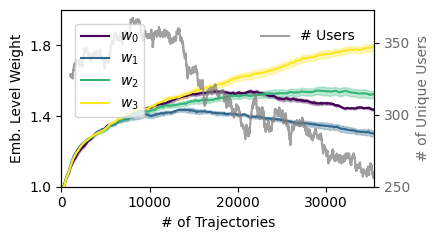

In [9]:
# Downsample: weights are logged twice per trajectory (pred + train forward pass).
weight_means_p = weight_means[:, ::2]
weight_stds_p = weight_stds[:, ::2]

fig, ax1 = plt.subplots(figsize=(4.5, 2.5))
cmap = plt.get_cmap("viridis", 4)
colors = cmap(range(4))

# Raw level weights w_l (optimization dynamics) + unique-user count.
for i in range(4):
    x = np.arange(len(weight_means_p[i]))
    ax1.plot(x, weight_means_p[i], label=rf"$w_{i}$", color=colors[i])
    ax1.fill_between(
        x,
        weight_means_p[i] - weight_stds_p[i],
        weight_means_p[i] + weight_stds_p[i],
        alpha=0.3,
        color=colors[i],
    )
ax1.set_xlim(0, x.max())
ax1.set_ylim(1, 2)

ax2 = ax1.twinx()
ax2.plot(n_unique.index, n_unique.to_numpy(), color="gray", alpha=0.75, label="# Users")
ax2.tick_params(axis="y", labelcolor="dimgray")

legend_1 = ax1.legend(loc=2, borderaxespad=1.0)
legend_1.remove()
ax2.legend(loc=1, borderaxespad=1.0, frameon=False)
ax2.add_artist(legend_1)
ax1.set_xlabel("# of Trajectories")
ax1.set_ylabel("Emb. Level Weight")
ax2.set_ylabel("# of Unique Users", color="dimgray")
ax1.set_xticks(ax1.get_xticks()[:-1:2])
ax1.set_yticks(ax1.get_yticks()[::2])
ax2.set_yticks(ax2.get_yticks()[:-1:2])

fig.tight_layout()
fig.savefig("../pub/figs/level_weights.pdf", bbox_inches="tight")

## Per-level contribution share: MiLES vs. $-$WL

Identifiable per-level forward-contribution magnitude $g_l = w_l\,\lVert z_l\rVert\,\lVert W_l\rVert$ (level weight $\times$ embedding row norm $\times$ first-layer input-block column norm). Plotting its share $g_l/\sum_l g_l$ shows how MiLES re-weights the levels through the scalar $w_l$, while $-$WL (no weights) can only do so through the high-dimensional input block and stays near its initialization profile.

In [2]:
gain = pd.concat(
    [
        pd.read_json("../reports/level_gain_miles.jsonl", lines=True).assign(model="MiLES"),
        pd.read_json("../reports/level_gain_nowl.jsonl", lines=True).assign(model="-WL"),
    ],
    ignore_index=True,
)

In [3]:
def share_traj(frame):
    """Mean-over-seeds per-level share of g_l = w_l * ||z_l|| * ||W_l||."""
    weighted = (frame["embedding_type"] == "lookup_weighted_concat").iloc[0]
    stack = lambda p: np.stack(  # (seeds, T, 4)
        [np.stack(frame[f"{p}_{i}"]) for i in range(4)], axis=-1
    )
    E, W = stack("embedding_norm"), stack("input_weight_norm")
    wl = stack("embedding_weight") if weighted else np.ones_like(W)
    g = wl * E * W
    return (g / g.sum(-1, keepdims=True)).mean(0)  # (T, 4)


shares = {model: share_traj(frame) for model, frame in gain.groupby("model")}

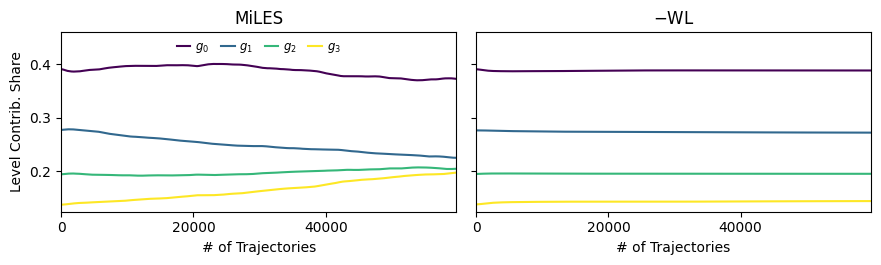

In [10]:
def smooth(a, w=1500):
    """Rolling mean so the per-step share is legible."""
    return np.convolve(a, np.ones(w) / w, mode="valid")


fig, axes = plt.subplots(1, 2, figsize=(9, 2.75), sharey=True)
for ax, (model, title) in zip(axes, [("MiLES", "MiLES"), ("-WL", r"$-$WL")]):
    sh = shares[model]
    for i in range(4):
        m = smooth(sh[:, i])
        x = np.arange(len(m))
        ax.plot(x, m, label=rf"$g_{i}$", color=colors[i])
    ax.set_xlim(0, x.max())
    ax.set_xlabel("# of Trajectories")
    ax.set_title(title)
    ax.set_xticks(ax.get_xticks()[:-1:2])

axes[0].set_ylim(top=0.46)
axes[0].set_ylabel("Level Contrib. Share")
axes[0].legend(
    loc="upper center",
    frameon=False,
    ncol=4,
    fontsize="small",
    borderaxespad=0.3,
    columnspacing=1.0,
    handletextpad=0.4,
    handlelength=1.2,
)

fig.tight_layout()
fig.savefig("../pub/figs/level_gain.pdf", bbox_inches="tight")

## Absolute components of $g_l$ (appendix)

Decompose $g_l = w_l\,\lVert Z_l\rVert\,\lVert W_l\rVert$ into its three factors (one per row) for MiLES vs. $-$WL. The embedding and input-weight norms barely differ between the two models or across levels, so the per-level re-weighting is carried by $w_l$ alone ($-$WL keeps $w_l = 1$).

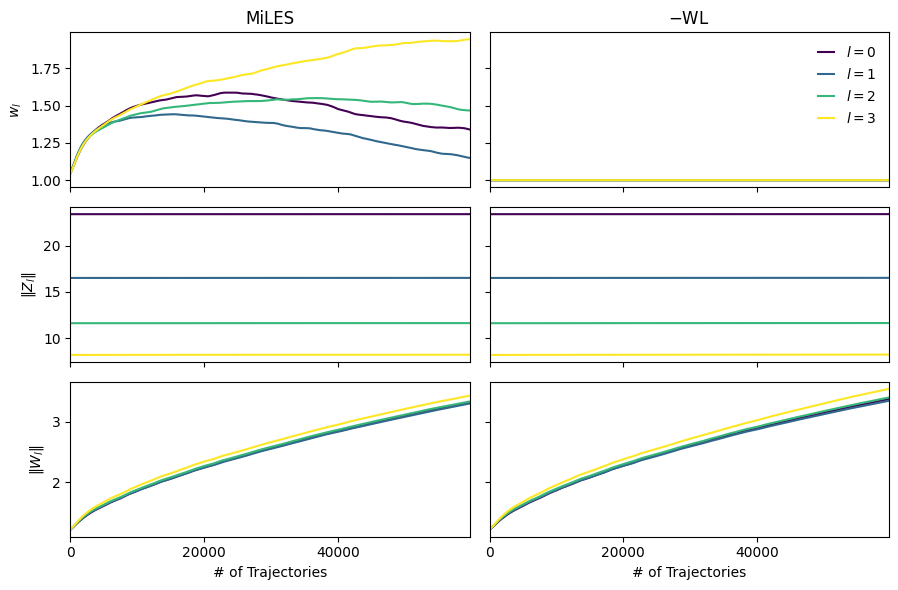

In [9]:
component_specs = [
    ("embedding_weight", r"$w_l$"),
    ("embedding_norm", r"$\|Z_l\|$"),
    ("input_weight_norm", r"$\|W_l\|$"),
]


def component_means(frame, prefix):
    """Mean-over-seeds per-level absolute component; w_l == 1 for the -WL model."""
    weighted = (frame["embedding_type"] == "lookup_weighted_concat").iloc[0]
    if prefix == "embedding_weight" and not weighted:
        length = len(frame.iloc[0]["embedding_norm_0"])
        return np.ones((length, 4))
    stacked = np.stack([np.stack(frame[f"{prefix}_{i}"]) for i in range(4)], axis=-1)
    return stacked.mean(0)  # (T, 4)


fig, axes = plt.subplots(3, 2, figsize=(9, 6), sharex=True, sharey="row")
for row, (prefix, ylabel) in enumerate(component_specs):
    for col, (model, title) in enumerate([("MiLES", "MiLES"), ("-WL", r"$-$WL")]):
        ax = axes[row, col]
        comp = component_means(gain[gain["model"] == model], prefix)
        for i in range(4):
            m = smooth(comp[:, i])
            x = np.arange(len(m))
            ax.plot(x, m, color=colors[i], label=rf"$l={i}$")
        ax.set_xlim(0, x.max())
        if row == 0:
            ax.set_title(title)
        if row == len(component_specs) - 1:
            ax.set_xlabel("# of Trajectories")
        if col == 0:
            ax.set_ylabel(ylabel)

# Set the (shared) x-ticks once; per-axis decimation would compound under sharex.
axes[-1, 0].set_xticks(np.arange(0, x.max(), 20000))

# w_l == 1 for -WL leaves the top-right panel empty, so the legend fits there.
axes[0, 1].legend(loc="upper right", ncol=1, frameon=False, handlelength=1.2)
fig.tight_layout()
fig.savefig("../pub/figs/level_gain_components.pdf", bbox_inches="tight")